# OSFI Regulation Assistant: a RAG project
## Part 4: Evaluate, fix, and measure the improvement (round 2)

**Round 1 of this evaluation found that labelling definition passages did not help.** The *Key Terms › Model* definition still wasn't in the top 10 for *"How does OSFI define a model?"*. A diagnostic showed two root causes:
1. **The re-ranker only saw the top 20 candidates.** When the first stage ranked the definition 9th, the re-ranker moved it to 1st, but for most phrasings it ranked below 20, so the re-ranker never saw it.
2. **Keyword search didn't recognize word variants.** "define", "defines" and "definition" counted as different words.

**Round 2 fixes:** stemming in keyword search, and a larger candidate pool (50) for the re-ranker. The prompt was also adjusted to stop adding "not covered" notes by habit, and partial answers are detected more reliably.

This notebook runs an **ablation study**, adding one fix at a time, to show which change actually helped:

| Configuration | Label definitions | Stemming | Re-ranker pool |
|---|---|---|---|
| A. Original | no | no | 20 |
| B. + label | yes | no | 20 |
| C. + stemming | yes | yes | 20 |
| D. + larger pool (final) | yes | yes | 50 |

It **reuses the test set saved in round 1**, so the comparison is fair.

**Runtime: T4 GPU required.** About 10–15 minutes.

## Step 1: Start Ollama and load everything from Parts 2 and 3

In [ ]:
!apt-get -qq install -y zstd pciutils lshw > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null
!pip -q install sentence-transformers rank_bm25 faiss-cpu nltk

import subprocess, time, requests
server = subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(30):
    try:
        requests.get("http://localhost:11434", timeout=2); print("Ollama server is running"); break
    except Exception:
        time.sleep(1)

>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 67.4 MB/s eta 0:00:00
Ollama server is running


In [ ]:
import os, sys, json, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/osfi_rag_project"
except Exception as e:
    print("Drive not available, using a local folder:", e)
    PROJECT_DIR = "osfi_rag_project"

INDEX_DIR = os.path.join(PROJECT_DIR, "index")
CODE_DIR = os.path.join(PROJECT_DIR, "osfi_rag")
EVAL_DIR = os.path.join(PROJECT_DIR, "evaluation"); os.makedirs(EVAL_DIR, exist_ok=True)
sys.path.insert(0, PROJECT_DIR)

config = json.load(open(os.path.join(INDEX_DIR, "config.json")))
gen_config = json.load(open(os.path.join(INDEX_DIR, "generation_config.json")))
LLM_MODEL = gen_config["llm_model"]
print("Embedding model:", config["embed_model"], "| LLM:", LLM_MODEL,
      "| relevance threshold from Part 3:", gen_config["min_relevance"])

Mounted at /content/drive
Embedding model: BAAI/bge-small-en-v1.5 | LLM: qwen2.5:7b | relevance threshold from Part 3: -1.99


In [ ]:
!ollama pull {LLM_MODEL} 2>&1 | tail -1

success 


## Step 2: Save the updated modules and build the four configurations

- **`retriever.py` (version 2)** adds **stemming** to keyword search (NLTK's Porter stemmer: *define*, *defines*, *defining* → *defin*) and a **configurable re-ranker pool**.
- **`enrichment.py`** labels passages under headings like *Key Terms*, *Definitions*, or *Glossary*: *Definition of the term "Model". This passage defines what "Model" means.* Only the text used for **search** changes. The passage shown to the LLM and users stays exactly as OSFI wrote it.
- **`generator.py` (version 3)** detects partial answers with or without a colon, and tells the LLM to add a "not covered" note only when the question asks for something specific the passages lack.

In [ ]:
%%writefile {CODE_DIR}/retriever.py
"""Hybrid retrieval over OSFI guideline chunks (version 2).

Combines keyword search (BM25) with semantic search (embeddings + cosine
similarity), merges the two rankings with Reciprocal Rank Fusion, and can
re-rank the merged candidates with a cross-encoder.

Version 2 changes, from the Part 4 evaluation:
- Keyword search stems words, so "define", "defines" and "definition" match.
- The re-ranker sees 50 candidates instead of 20, since it can only promote
  passages that the first stage retrieved.
"""
from __future__ import annotations

import json
import os
import re
from dataclasses import dataclass, asdict

import faiss
import numpy as np
from nltk.stem import PorterStemmer
from rank_bm25 import BM25Okapi

STOPWORDS = set("""a an and are as at be by can do does for from has have how i in is it its
of on or should that the their them these this to under was what when which who why will
with""".split())

# BGE embedding models work best when search queries carry this instruction
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "


_stemmer = PorterStemmer()


def tokenize(text: str, stem: bool = True) -> list[str]:
    """Lower-case words for BM25, keeping acronyms like GDS and numbers like 80.
    With stem=True, words are reduced to their root: define/defines/defining -> defin."""
    words = [w for w in re.findall(r"[a-z0-9]+(?:[-'][a-z0-9]+)*", text.lower()) if w not in STOPWORDS]
    return [_stemmer.stem(w) for w in words] if stem else words


@dataclass
class SearchResult:
    rank: int
    score: float
    chunk_id: str
    doc_id: str
    section: str
    text: str
    url: str

    def to_dict(self) -> dict:
        return asdict(self)


class HybridRetriever:
    """Keyword + semantic search over a list of chunk dictionaries."""

    def __init__(self, chunks: list[dict], embedder, reranker=None, rrf_k: int = 60,
                 stem: bool = True, rerank_candidates: int = 50):
        self.chunks = chunks
        self.embedder = embedder
        self.reranker = reranker
        self.rrf_k = rrf_k
        self.stem = stem
        self.rerank_candidates = rerank_candidates
        self.bm25 = BM25Okapi([tokenize(c["embed_text"], stem) for c in chunks])
        self.index = None

    # ---------- building and saving the vector index ----------
    def build_index(self, batch_size: int = 32) -> np.ndarray:
        vectors = self.embedder.encode([c["embed_text"] for c in self.chunks], batch_size=batch_size,
                                       normalize_embeddings=True, show_progress_bar=True)
        self._set_vectors(np.asarray(vectors, dtype="float32"))
        return self.vectors

    def _set_vectors(self, vectors: np.ndarray) -> None:
        self.vectors = vectors
        # Inner product on unit-length vectors equals cosine similarity
        self.index = faiss.IndexFlatIP(vectors.shape[1])
        self.index.add(vectors)

    def save(self, folder: str) -> None:
        os.makedirs(folder, exist_ok=True)
        np.save(os.path.join(folder, "embeddings.npy"), self.vectors)
        with open(os.path.join(folder, "chunks.jsonl"), "w", encoding="utf-8") as f:
            for c in self.chunks:
                f.write(json.dumps(c, ensure_ascii=False) + "\n")

    @classmethod
    def load(cls, folder: str, embedder, reranker=None, **kwargs) -> "HybridRetriever":
        with open(os.path.join(folder, "chunks.jsonl"), encoding="utf-8") as f:
            chunks = [json.loads(line) for line in f]
        retriever = cls(chunks, embedder, reranker, **kwargs)
        retriever._set_vectors(np.load(os.path.join(folder, "embeddings.npy")))
        return retriever

    # ---------- individual search methods (return (chunk index, score) pairs) ----------
    def keyword_search(self, query: str, k: int = 20) -> list[tuple[int, float]]:
        scores = self.bm25.get_scores(tokenize(query, self.stem))
        top = np.argsort(scores)[::-1][:k]
        return [(int(i), float(scores[i])) for i in top if scores[i] > 0]

    def semantic_search(self, query: str, k: int = 20) -> list[tuple[int, float]]:
        q = self.embedder.encode([QUERY_INSTRUCTION + query], normalize_embeddings=True)
        scores, ids = self.index.search(np.asarray(q, dtype="float32"), k)
        return [(int(i), float(s)) for i, s in zip(ids[0], scores[0]) if i != -1]

    def hybrid_search(self, query: str, k: int = 20, candidates: int | None = None) -> list[tuple[int, float]]:
        """Reciprocal Rank Fusion: reward chunks that rank well in either list."""
        candidates = candidates or max(30, k)
        fused: dict[int, float] = {}
        for ranking in (self.keyword_search(query, candidates), self.semantic_search(query, candidates)):
            for rank, (i, _) in enumerate(ranking, start=1):
                fused[i] = fused.get(i, 0.0) + 1.0 / (self.rrf_k + rank)
        return sorted(fused.items(), key=lambda x: x[1], reverse=True)[:k]

    def rerank(self, query: str, hits: list[tuple[int, float]], k: int) -> list[tuple[int, float]]:
        """A cross-encoder reads the question and each passage together, which is slower but more precise."""
        if self.reranker is None or not hits:
            return hits[:k]
        scores = self.reranker.predict([(query, self.chunks[i]["embed_text"]) for i, _ in hits])
        order = np.argsort(scores)[::-1][:k]
        return [(hits[j][0], float(scores[j])) for j in order]

    # ---------- the main entry point ----------
    def search(self, query: str, k: int = 5, method: str = "hybrid_rerank") -> list[SearchResult]:
        if method == "keyword":
            hits = self.keyword_search(query, k)
        elif method == "semantic":
            hits = self.semantic_search(query, k)
        elif method == "hybrid":
            hits = self.hybrid_search(query, k)
        elif method == "hybrid_rerank":
            hits = self.rerank(query, self.hybrid_search(query, self.rerank_candidates), k)
        else:
            raise ValueError(f"Unknown method: {method}")
        return [SearchResult(rank=r, score=round(s, 4), chunk_id=self.chunks[i]["chunk_id"],
                             doc_id=self.chunks[i]["doc_id"], section=self.chunks[i]["section"],
                             text=self.chunks[i]["text"], url=self.chunks[i]["url"])
                for r, (i, s) in enumerate(hits, start=1)]

Overwriting /content/drive/MyDrive/osfi_rag_project/osfi_rag/retriever.py


In [ ]:
%%writefile {CODE_DIR}/enrichment.py
"""Make definition passages findable.

Definitions rarely repeat the term they define ("Model: An application of theoretical,
empirical... techniques"). The term appears only in the heading, so search ranks the
definition below neighbouring passages that mention the word many times. This adds an
explicit label to the text used for search."""
from __future__ import annotations

DEFINITION_SECTIONS = ("key terms", "definitions", "glossary", "defined terms")


def defined_term(section: str) -> str | None:
    """Return the term if this section is a definition entry, e.g. 'A.4 Key Terms › Model' -> 'Model'."""
    parts = [p.strip() for p in section.split("›")]
    for i, part in enumerate(parts[:-1]):
        if any(key in part.lower() for key in DEFINITION_SECTIONS):
            return parts[-1]
    return None


def enrich_definitions(chunks: list[dict]) -> tuple[list[dict], int]:
    """Return copies of the chunks with definition passages labelled, plus how many were changed."""
    enriched, changed = [], 0
    for c in chunks:
        c = dict(c)
        term = defined_term(c["section"])
        if term:
            label = f'Definition of the term "{term}". This passage defines what "{term}" means.'
            c["embed_text"] = f"{label}\n{c['embed_text']}"
            changed += 1
        enriched.append(c)
    return enriched, changed

Overwriting /content/drive/MyDrive/osfi_rag_project/osfi_rag/enrichment.py


In [ ]:
%%writefile {CODE_DIR}/generator.py
"""Grounded answer generation: retrieve OSFI passages, then ask an LLM to answer
using only those passages, with numbered citations that are checked afterwards.

Version 2: partial answers get their own status, so a hedged answer that cites
passages is no longer counted as a refusal.
Version 3: partial answers are detected with or without the colon, and the prompt
discourages adding "not covered" notes by habit."""
from __future__ import annotations

import re
import time
from dataclasses import dataclass, field

import requests

NOT_FOUND = "I can't find this in the OSFI documents provided."
PARTIAL_MARKER = "The passages do not cover:"

SYSTEM_PROMPT = f"""You are an assistant that answers questions about Canadian financial regulation
using ONLY the numbered passages from OSFI guidelines provided by the user.

Rules:
1. Use only facts stated in the passages. Do not use outside knowledge.
2. After every sentence that uses a passage, cite it with its number in square brackets, like [1] or [2][3].
3. If NONE of the passages helps answer the question, reply with exactly this sentence and nothing else:
   {NOT_FOUND}
4. If the question asks for something specific that the passages do not contain, answer the rest with
   citations, then end with one sentence starting "{PARTIAL_MARKER}" naming that specific thing.
   Do NOT add this sentence just because more detail could exist: if the passages answer what was asked,
   simply answer. Never use the sentence from rule 3 in an answer that also contains information.
5. Each passage shows its document and section heading. A passage under a heading such as
   "Key Terms > Model" is the definition of that term, even if the term itself is not repeated in the text.
6. Be concise: at most 5 sentences, in plain language."""


class OllamaClient:
    """Minimal client for a local Ollama server's chat endpoint."""

    def __init__(self, model: str, host: str = "http://localhost:11434", temperature: float = 0.0,
                 num_ctx: int = 8192, timeout: int = 300):
        self.model, self.host, self.timeout = model, host, timeout
        self.options = {"temperature": temperature, "num_ctx": num_ctx}

    def chat(self, messages: list[dict], temperature: float | None = None) -> str:
        options = dict(self.options)
        if temperature is not None:
            options["temperature"] = temperature
        r = requests.post(f"{self.host}/api/chat", timeout=self.timeout,
                          json={"model": self.model, "messages": messages, "stream": False,
                                "options": options})
        r.raise_for_status()
        return r.json()["message"]["content"].strip()


@dataclass
class Answer:
    question: str
    answer: str
    status: str                      # "answered", "partial" or "refused"
    citations: list[int]
    invalid_citations: list[int]
    sources: list[dict]
    top_relevance: float | None
    seconds: float
    warnings: list[str] = field(default_factory=list)

    @property
    def refused(self) -> bool:
        return self.status == "refused"


class RAGAssistant:
    """Retrieve passages, build a grounded prompt, call the LLM, and validate the citations."""

    def __init__(self, retriever, llm, k: int = 5, min_relevance: float | None = None):
        self.retriever, self.llm, self.k = retriever, llm, k
        self.min_relevance = min_relevance   # optional guardrail on the re-ranker score

    @staticmethod
    def format_passages(results) -> str:
        return "\n\n".join(f"[{r.rank}] ({r.doc_id} > {r.section.replace(' › ', ' > ')})\n{r.text}"
                           for r in results)

    def answer(self, question: str) -> Answer:
        t0 = time.time()
        results = self.retriever.search(question, k=self.k, method="hybrid_rerank")
        top = results[0].score if results else None

        # Guardrail 1: if nothing relevant was retrieved, don't ask the LLM at all
        if not results or (self.min_relevance is not None and top < self.min_relevance):
            return Answer(question, NOT_FOUND, "refused", [], [], [], top, round(time.time() - t0, 2),
                          ["No passage passed the relevance threshold; the LLM was not called."])

        user_msg = f"Passages:\n\n{self.format_passages(results)}\n\nQuestion: {question}"
        text = self.llm.chat([{"role": "system", "content": SYSTEM_PROMPT},
                              {"role": "user", "content": user_msg}])

        # Guardrail 2: check every citation points to a passage that was actually provided
        cited = sorted({int(n) for n in re.findall(r"\[(\d+)\]", text)})
        valid = [n for n in cited if 1 <= n <= len(results)]
        invalid = [n for n in cited if n not in valid]
        says_not_found = NOT_FOUND.lower().rstrip(".") in text.lower()
        if says_not_found and not valid:
            status = "refused"
        elif says_not_found or re.search(r"passages do not (cover|contain|include|address)", text, re.I):
            status = "partial"
        else:
            status = "answered"

        warnings = []
        if invalid:
            warnings.append(f"Answer cites passages that were not provided: {invalid}")
        if status != "refused" and not valid:
            warnings.append("Answer has no citations, so it may not be grounded in the documents.")

        sources = [{"n": r.rank, "doc_id": r.doc_id, "section": r.section, "url": r.url,
                    "chunk_id": r.chunk_id, "relevance": r.score, "cited": r.rank in valid}
                   for r in results]
        return Answer(question, text, status, valid, invalid, sources, top,
                      round(time.time() - t0, 2), warnings)

Overwriting /content/drive/MyDrive/osfi_rag_project/osfi_rag/generator.py


In [ ]:
import importlib, torch, nltk
import osfi_rag.retriever, osfi_rag.generator, osfi_rag.enrichment
for m in (osfi_rag.retriever, osfi_rag.generator, osfi_rag.enrichment):
    importlib.reload(m)
from osfi_rag.retriever import HybridRetriever, tokenize
from osfi_rag.generator import OllamaClient, RAGAssistant, NOT_FOUND
from osfi_rag.enrichment import enrich_definitions, defined_term
from sentence_transformers import SentenceTransformer, CrossEncoder

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(config["embed_model"], device=DEVICE)
reranker = CrossEncoder(config["rerank_model"], device=DEVICE)

# A: the original index from Part 2, with the original settings
original = HybridRetriever.load(INDEX_DIR, embedder, reranker, stem=False, rerank_candidates=20)
enriched_chunks, n_changed = enrich_definitions(original.chunks)

def labelled(stem, pool):
    r = HybridRetriever(enriched_chunks, embedder, reranker, stem=stem, rerank_candidates=pool)
    if labelled.vectors is None:
        labelled.vectors = r.build_index()          # embed the labelled chunks once...
    else:
        r._set_vectors(labelled.vectors)            # ...and reuse the vectors for the other configurations
    return r
labelled.vectors = None

CONFIGS = {
    "A. original": original,
    "B. + label": labelled(stem=False, pool=20),
    "C. + stemming": labelled(stem=True, pool=20),
    "D. + larger pool": labelled(stem=True, pool=50),
}
final = CONFIGS["D. + larger pool"]
baseline = original
print(f"{n_changed} definition passages labelled")
print("Stemming example:", tokenize("How does OSFI define a model? This passage defines it.", stem=True))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

13 definition passages labelled
Stemming example: ['osfi', 'defin', 'model', 'passag', 'defin']


## Step 3: Build the test set

**Part A: generated questions with a known answer passage.** We pick about 40 passages, spread across all six documents, and ask the LLM to write one question each passage answers, **in different words** so the test isn't just keyword matching. Since we know which passage each question came from, we can check whether search finds that exact passage. This is a standard way to evaluate RAG systems when there's no labelled dataset.

**Limitation to be aware of:** generated questions tend to be easier and more literal than real users' questions, so treat these scores as optimistic. That's why the hand-written and near-topic questions matter too.

**This round reuses the test set saved in round 1** (`evaluation/test_set.csv`), so the numbers are directly comparable. If that file doesn't exist, the questions are generated as described above.

In [ ]:
TEST_PATH = os.path.join(EVAL_DIR, "test_set.csv")
REUSE = os.path.exists(TEST_PATH)
print("Reusing the saved test set" if REUSE else "No saved test set found: generating questions")

Reusing the saved test set


In [ ]:
GEN_PROMPT = """Below is a passage from an OSFI regulatory guideline.

Document: {doc}
Section: {section}
Passage: {text}

Write ONE question that a bank compliance analyst might ask, which this passage answers.
Use your own words: do not copy phrases from the passage. Do not mention "the passage" or "the document".
Output only the question."""

llm = OllamaClient(LLM_MODEL)
if not REUSE:
  random.seed(42)
  eligible = [c for c in baseline.chunks if len(c["text"].split()) >= 30 and c["section"] != "Footnotes"]
  by_doc = {}
  for c in eligible:
      by_doc.setdefault(c["doc_id"], []).append(c)
  TARGET = 40
  sample = []
  for doc, cs in by_doc.items():
      n = min(len(cs), max(3, round(TARGET * len(cs) / len(eligible))))
      sample += random.sample(cs, n)

  generated = []
  for i, c in enumerate(sample, 1):
      q = llm.chat([{"role": "user", "content": GEN_PROMPT.format(doc=c["title"], section=c["section"], text=c["text"])}])
      q = q.strip().strip('"').split("\n")[0].strip()
      generated.append({"question": q, "type": "generated", "gold_chunk": c["chunk_id"], "gold_doc": c["doc_id"]})
      if i % 10 == 0:
          print(f"{i}/{len(sample)} questions generated")

  gen_df = pd.DataFrame(generated)
  print(f"\n{len(gen_df)} generated questions:", gen_df["gold_doc"].value_counts().to_dict())
  display(gen_df.sample(8, random_state=1)[["question", "gold_chunk"]])

**Part B: hand-written questions** from Part 3. Most only have a known *document*, not a specific passage. The definition question is checked against the exact *Key Terms › Model* passage.

**Part C: out-of-scope questions.** The five clearly unrelated ones from Part 3, plus **near-topic** questions about real OSFI subjects that these six documents **don't** cover (cyber risk, liquidity, climate). These are much harder to refuse correctly, because the vocabulary overlaps.

In [ ]:
model_def = [c["chunk_id"] for c in original.chunks
             if c["doc_id"] == "E-23" and c["section"].strip().lower().endswith("key terms › model")]
print("Definition passage for 'Model':", model_def or "NOT FOUND - check the E-23 section names")

HAND = [
    ("What is the minimum qualifying rate for uninsured mortgages?", "B-20", None),
    ("What is the maximum loan-to-value ratio for a HELOC?", "B-20", None),
    ("How should lenders calculate the GDS and TDS ratios?", "B-20", None),
    ("What should mortgage insurers check when verifying a borrower's income?", "B-21", None),
    ("How does OSFI define a model in its model risk guideline?", "E-23", model_def[0] if model_def else None),
    ("How should a bank work out the actual cost of mortgage insurance it charges borrowers?", "MI-NOTE", None),
    ("Do the B-20 rules apply to combined loan plans and other innovative lending products?", "B-20-CLAR", None),
    ("Why is high household debt a risk to Canada's financial system?", "B-20-INFO", None),
]
OUT = [
    ("What is the capital gains tax rate in Canada?", "unrelated"),
    ("How do I open a TFSA account?", "unrelated"),
    ("What is the best recipe for banana bread?", "unrelated"),
    ("Who is the current Governor of the Bank of Canada?", "unrelated"),
    ("What are the rules for cryptocurrency trading platforms?", "unrelated"),
    ("What does OSFI expect banks to do to manage cyber security risk?", "near-topic"),
    ("What liquidity coverage ratio must Canadian banks maintain?", "near-topic"),
    ("How should banks disclose climate-related financial risks?", "near-topic"),
    ("What capital must life insurance companies hold under OSFI rules?", "near-topic"),
    ("What are OSFI's expectations for third-party and outsourcing risk?", "near-topic"),
]
hand_df = pd.DataFrame([{"question": q, "type": "hand-written", "gold_doc": d, "gold_chunk": c} for q, d, c in HAND])
out_df = pd.DataFrame([{"question": q, "type": t} for q, t in OUT])
if REUSE:
    test_set = pd.read_csv(TEST_PATH)
else:
    test_set = pd.concat([gen_df, hand_df, out_df], ignore_index=True)
    test_set.to_csv(TEST_PATH, index=False)
print(test_set["type"].value_counts().to_string())

Definition passage for 'Model': ['E-23-005']
type
generated       42
hand-written     8
unrelated        5
near-topic       5


## Step 4: Evaluate retrieval for each configuration

For each question with a known passage, we find **where that passage ranks**:
- **Hit@k**: the share of questions whose correct passage appears in the top *k* results. Hit@5 matters most, since the LLM sees 5 passages.
- **MRR (Mean Reciprocal Rank)**: the average of 1 ÷ rank. Rank 1 scores 1, rank 2 scores 0.5, rank 5 scores 0.2, and not found scores 0.

In [ ]:
METHODS = ["keyword", "semantic", "hybrid", "hybrid_rerank"]
chunk_q = test_set[test_set["gold_chunk"].notna()]

def rank_of(retriever, question, gold, method, depth=10):
    ids = [r.chunk_id for r in retriever.search(question, k=depth, method=method)]
    return ids.index(gold) + 1 if gold in ids else None

rows = []
for name, r in CONFIGS.items():
    for m in METHODS:
        ranks = [rank_of(r, q, g, m) for q, g in zip(chunk_q["question"], chunk_q["gold_chunk"])]
        rows.append({"config": name, "method": m,
                     "hit@1": np.mean([x == 1 for x in ranks]),
                     "hit@3": np.mean([bool(x) and x <= 3 for x in ranks]),
                     "hit@5": np.mean([bool(x) and x <= 5 for x in ranks]),
                     "MRR": np.mean([1 / x if x else 0 for x in ranks])})
retrieval = pd.DataFrame(rows)
retrieval.to_csv(os.path.join(EVAL_DIR, "retrieval_metrics_round2.csv"), index=False)
print(f"{len(chunk_q)} questions with a known correct passage\n")
print("ABLATION: hybrid search + re-ranking, one fix at a time")
display(retrieval[retrieval["method"] == "hybrid_rerank"].set_index("config")[["hit@1", "hit@3", "hit@5", "MRR"]].round(3))
print("\nALL METHODS: original (A) vs final (D)")
display(retrieval[retrieval["config"].isin(["A. original", "D. + larger pool"])]
        .pivot(index="method", columns="config", values=["hit@1", "hit@5", "MRR"]).round(3).loc[METHODS])

43 questions with a known correct passage

ABLATION: hybrid search + re-ranking, one fix at a time


,hit@1,hit@3,hit@5,MRR
config,,,,
A. original,0.791,0.953,0.953,0.868
B. + label,0.791,0.953,0.953,0.868
C. + stemming,0.791,0.977,0.977,0.879
D. + larger pool,0.791,0.977,0.977,0.879



ALL METHODS: original (A) vs final (D)


hit@1                        hit@5                          MRR                 
config        A. original D. + larger pool A. original D. + larger pool A. original D. + larger pool
method                                                                                              
keyword             0.721            0.698       0.907            0.884       0.801            0.773
semantic            0.698            0.698       0.860            0.837       0.772            0.768
hybrid              0.721            0.698       0.884            0.907       0.809            0.785
hybrid_rerank       0.791            0.791       0.953            0.977       0.868            0.879

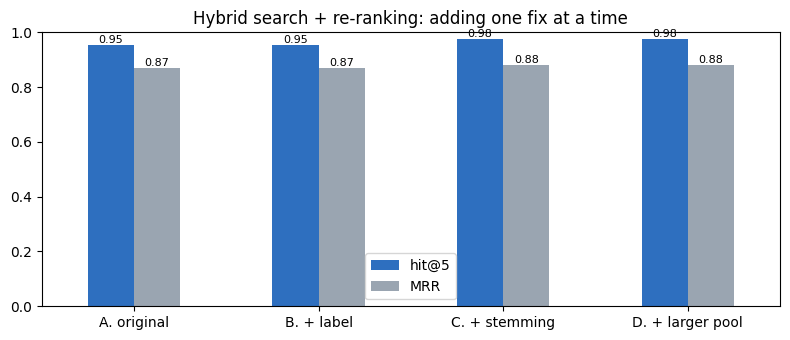

In [ ]:
abl = retrieval[retrieval["method"] == "hybrid_rerank"].set_index("config")[["hit@5", "MRR"]]
ax = abl.plot(kind="bar", figsize=(8, 3.5), color=["#2e6fbf", "#9aa5b1"], rot=0)
ax.set_ylim(0, 1); ax.set_xlabel("")
ax.set_title("Hybrid search + re-ranking: adding one fix at a time")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(EVAL_DIR, "ablation.png"), dpi=150); plt.show()

### The definition question, specifically

The rank of the *Key Terms › Model* definition for four phrasings, in each configuration, using hybrid search + re-ranking (the method the assistant uses). "not reached" means the first stage didn't place it among the passages the re-ranker sees.

In [ ]:
DEF_QS = ["How does OSFI define a model in its model risk guideline?",
          "What is a model?",
          "What is the definition of a model under Guideline E-23?",
          "What counts as a model for OSFI?"]
def full_rank(r, q):
    ids = [x.chunk_id for x in r.search(q, k=len(r.chunks), method="hybrid_rerank")]
    return ids.index(model_def[0]) + 1 if model_def[0] in ids else f"not reached (pool {r.rerank_candidates})"
if model_def:
    def_ranks = pd.DataFrame({name: {q[:50]: full_rank(r, q) for q in DEF_QS} for name, r in CONFIGS.items()})
    display(def_ranks)

,A. original,B. + label,C. + stemming,D. + larger pool
How does OSFI define a model in its model risk gui,not reached (pool 20),not reached (pool 20),2,2
What is a model?,not reached (pool 20),not reached (pool 20),not reached (pool 20),1
What is the definition of a model under Guideline,not reached (pool 20),1,1,1
What counts as a model for OSFI?,not reached (pool 20),not reached (pool 20),not reached (pool 20),not reached (pool 50)


### Document-level check for the hand-written questions

In [ ]:
doc_rows = []
for name in ["A. original", "D. + larger pool"]:
    for m in METHODS:
        hits = [any(h.doc_id == d for h in CONFIGS[name].search(q, k=3, method=m))
                for q, d in zip(hand_df["question"], hand_df["gold_doc"])]
        doc_rows.append({"config": name, "method": m, "expected document in top 3": f"{sum(hits)}/{len(hits)}"})
pd.DataFrame(doc_rows).pivot(index="method", columns="config", values="expected document in top 3").loc[METHODS]

config,A. original,D. + larger pool
method,,
keyword,7/8,8/8
semantic,8/8,8/8
hybrid,8/8,8/8
hybrid_rerank,8/8,8/8


## Step 5: Evaluate the answers

Using the **final configuration (D)** with hybrid search plus re-ranking, the **version 3 prompt**, and the relevance threshold from Part 3, we answer every question and record:
- **Status**: answered, partial, or refused
- **Correct passage cited**: for questions with a known passage, did the answer cite it?
- **Out-of-scope handling**: were unrelated and near-topic questions refused?

In [ ]:
MIN_RELEVANCE = gen_config["min_relevance"]
assistant = RAGAssistant(final, llm, k=5, min_relevance=MIN_RELEVANCE)

results = []
for i, row in enumerate(test_set.itertuples(), 1):
    a = assistant.answer(row.question)
    cited_ids = [s["chunk_id"] for s in a.sources if s["cited"]]
    retrieved_ids = [s["chunk_id"] for s in a.sources]
    gold = row.gold_chunk if isinstance(row.gold_chunk, str) else None
    results.append({
        "question": row.question, "type": row.type, "status": a.status, "answer": a.answer,
        "gold_retrieved": (gold in retrieved_ids) if gold else None,
        "gold_cited": (gold in cited_ids) if gold else None,
        "n_citations": len(a.citations), "invalid_citations": len(a.invalid_citations),
        "top_relevance": a.top_relevance, "seconds": a.seconds,
        "passages": "\n\n".join(f"[{s['n']}] " + next(c["text"] for c in final.chunks if c["chunk_id"] == s["chunk_id"])
                                 for s in a.sources),
    })
    if i % 10 == 0:
        print(f"{i}/{len(test_set)} answered")
res = pd.DataFrame(results)

10/60 answered
20/60 answered
30/60 answered
40/60 answered
50/60 answered
60/60 answered


In [ ]:
in_scope = res[~res["type"].isin(["unrelated", "near-topic"])]
print("STATUS BY QUESTION TYPE")
display(pd.crosstab(res["type"], res["status"]))

with_gold = in_scope[in_scope["gold_cited"].notna()]
print(f"\nIn scope: {(in_scope['status'] != 'refused').mean():.0%} answered or partly answered "
      f"({len(in_scope)} questions)")
print(f"Correct passage retrieved in top 5: {with_gold['gold_retrieved'].astype(bool).mean():.0%} | "
      f"correct passage cited: {with_gold['gold_cited'].astype(bool).mean():.0%} ({len(with_gold)} questions)")
print(f"Invalid citations: {res['invalid_citations'].sum()}")
print(f"Seconds per answer: median {res['seconds'].median():.1f}, 90th percentile {res['seconds'].quantile(0.9):.1f}")

STATUS BY QUESTION TYPE


status,answered,partial,refused
type,,,
generated,22,20,0
hand-written,4,4,0
near-topic,0,3,2
unrelated,0,0,5



In scope: 100% answered or partly answered (50 questions)
Correct passage retrieved in top 5: 98% | correct passage cited: 91% (43 questions)
Invalid citations: 0
Seconds per answer: median 3.3, 90th percentile 6.1


In [ ]:
print("HAND-WRITTEN QUESTIONS (including the two from Part 3)")
for r in res[res["type"] == "hand-written"].itertuples():
    print(f"\n[{r.status.upper()}] {r.question}\n{r.answer}")

HAND-WRITTEN QUESTIONS (including the two from Part 3)

[ANSWERED] What is the minimum qualifying rate for uninsured mortgages?
The minimum qualifying rate for uninsured mortgages is the greater of the contractual mortgage rate plus 2% or 5.25%. [1]

[ANSWERED] What is the maximum loan-to-value ratio for a HELOC?
OSFI expects the maximum authorized LTV ratio for a non-amortizing HELOC component of a residential mortgage to be less than or equal to 65 percent. [2][4]

[PARTIAL] How should lenders calculate the GDS and TDS ratios?
Lenders should calculate GDS and TDS ratios conservatively, including principal and interest payments on the mortgage loan, primary and other sources of income, heating costs, property taxes, condominium or strata fees, and payments for all other credit facilities. [1][2] The passages do not cover the specific formulae or detailed steps for calculation.

[PARTIAL] What should mortgage insurers check when verifying a borrower's income?
FRMIs should specify proce

In [ ]:
print("OUT-OF-SCOPE QUESTIONS")
display(res[res["type"].isin(["unrelated", "near-topic"])][["type", "question", "status", "top_relevance"]])

OUT-OF-SCOPE QUESTIONS


,type,question,status,top_relevance
50,unrelated,What is the capital gains tax rate in Canada?,refused,-7.9553
51,unrelated,How do I open a TFSA account?,refused,-10.4768
52,unrelated,What is the best recipe for banana bread?,refused,-11.0317
53,unrelated,Who is the current Governor of the Bank of Canada?,refused,-8.7490
54,unrelated,What are the rules for cryptocurrency trading platforms?,refused,-10.7350
55,near-topic,What does OSFI expect banks to do to manage cyber security risk?,partial,-0.4435
56,near-topic,What liquidity coverage ratio must Canadian banks maintain?,refused,-5.7790
57,near-topic,How should banks disclose climate-related financial risks?,refused,-6.7190
58,near-topic,What capital must life insurance companies hold under OSFI rules?,partial,0.5307
59,near-topic,What are OSFI's expectations for third-party and outsourcing risk?,partial,2.7263


In [ ]:
# Compare answer statuses with round 1, if its results were saved
r1_path = os.path.join(EVAL_DIR, "answers.csv")
if os.path.exists(r1_path):
    r1 = pd.read_csv(r1_path)
    if "status" in r1.columns and len(r1) == len(res):
        comp = pd.DataFrame({"round 1": r1["status"].value_counts(), "round 2": res["status"].value_counts()}).fillna(0).astype(int)
        print("ANSWER STATUS, ROUND 1 vs ROUND 2 (all questions)")
        display(comp)
        d = res["question"].str.startswith("How does OSFI define a model")
        if d.any():
            print("Definition question:", r1.loc[d.values, "status"].iloc[0], "->", res.loc[d, "status"].iloc[0])

ANSWER STATUS, ROUND 1 vs ROUND 2 (all questions)


,round 1,round 2
status,,
partial,30,27
answered,20,26
refused,10,7


Definition question: refused -> answered


## Step 6: Is each answer supported by its passages? (LLM as a judge)

Citations show *where* an answer claims its facts came from, not whether the passages really say that. To check, we give the LLM each answer with its passages and ask whether every claim is supported. This is called **LLM-as-a-judge**.

**An important limitation:** the judge is the same model that wrote the answers, so it may be too lenient with itself. That's why Step 7 asks **you** to check a sample by hand and compare.

In [ ]:
JUDGE_PROMPT = """You are checking whether an answer is fully supported by source passages.

PASSAGES:
{passages}

ANSWER:
{answer}

Is every factual claim in the ANSWER stated in the PASSAGES? Ignore the citation numbers.
Reply with exactly one word: SUPPORTED, PARTIAL, or UNSUPPORTED."""

def judge(passages, answer):
    out = llm.chat([{"role": "user", "content": JUDGE_PROMPT.format(passages=passages, answer=answer)}]).upper()
    for label in ("UNSUPPORTED", "PARTIAL", "SUPPORTED"):
        if label in out:
            return label
    return "UNCLEAR"

to_judge = res["status"] != "refused"
res.loc[to_judge, "judge"] = [judge(p, a) for p, a in zip(res.loc[to_judge, "passages"], res.loc[to_judge, "answer"])]
print("Judge verdicts for answered and partial responses:")
res.loc[to_judge, "judge"].value_counts().to_frame()

Judge verdicts for answered and partial responses:


,count
judge,
SUPPORTED,46
PARTIAL,4
UNSUPPORTED,3


## Step 7: Your own spot check

The next cell shows **10 randomly chosen answers** with the passages they were based on. Read each one and decide: are all its claims stated in the passages?

Then type your verdicts in the cell after it, in the same order, using `"S"` (supported), `"P"` (partly supported) or `"U"` (unsupported), and run it to see how often you agree with the judge. This step is optional, but valuable: if you and the judge mostly agree, its numbers are more trustworthy, and it's a strong point to mention in interviews.

In [ ]:
spot = res[to_judge].sample(min(10, int(to_judge.sum())), random_state=7)
for n, r in enumerate(spot.itertuples(), 1):
    print(f"===== {n}. {r.question}\nANSWER: {r.answer}\n\nPASSAGES:\n{r.passages[:1500]}\n")

===== 1. What steps should a mortgage insurer take to ensure the ongoing performance and suitability of automated underwriting systems and models?
ANSWER: A mortgage insurer should establish an independent validation process for automated underwriting systems at initial implementation and on a periodic basis [1]. They should also maintain mechanisms for detecting and preventing fraud or misrepresentation [1]. Additionally, insurers should recalibrate associated parameters based on findings from file reviews [1]. The insurer should continuously monitor and audit the information received on mortgage loans to reduce inaccuracies and detect fraud [2]. Back-testing processes should be used [2].

PASSAGES:
[1] Automated underwriting systems and other models are commonly used to help an insurer efficiently assess the risk of insuring a mortgage loan (or a group of mortgage loans). Given the importance of underwriting systems and other models to mortgage insurance underwriting, a FRMI should e

In [ ]:
MY_LABELS = []   # e.g. ["S", "S", "P", "S", "U", "S", "S", "S", "P", "S"]

codes = {"S": "SUPPORTED", "P": "PARTIAL", "U": "UNSUPPORTED"}
if len(MY_LABELS) == len(spot):
    check = spot[["question", "judge"]].assign(your_label=[codes[x.strip().upper()] for x in MY_LABELS])
    check.to_csv(os.path.join(EVAL_DIR, "human_check_round2.csv"), index=False)
    agreement = (check["your_label"] == check["judge"]).mean()
    print(f"You agree with the judge on {agreement:.0%} of {len(check)} answers.")
    display(check)
else:
    agreement = None
    print(f"Add {len(spot)} labels to MY_LABELS (you have {len(MY_LABELS)}), then rerun this cell.")

Add 10 labels to MY_LABELS (you have 0), then rerun this cell.


## Step 8: Save the results

In [ ]:
best = retrieval[(retrieval["config"] == "D. + larger pool") & (retrieval["method"] == "hybrid_rerank")].iloc[0]
before = retrieval[(retrieval["config"] == "A. original") & (retrieval["method"] == "hybrid_rerank")].iloc[0]
out_scope = res[res["type"].isin(["unrelated", "near-topic"])]
judged = res.loc[to_judge, "judge"]
summary = {
    "llm_model": LLM_MODEL, "embed_model": config["embed_model"], "rerank_model": config["rerank_model"],
    "chunks": len(final.chunks), "definition_passages_labelled": n_changed,
    "final_config": {"label_definitions": True, "stemming": True, "rerank_candidates": final.rerank_candidates},
    "definition_rank_before": str(def_ranks.iloc[0, 0]) if model_def else None,
    "definition_rank_after": str(def_ranks.iloc[0, -1]) if model_def else None,
    "partial_share_in_scope": round(float((in_scope["status"] == "partial").mean()), 3),
    "test_questions": int(len(res)), "questions_with_known_passage": int(len(chunk_q)),
    "hybrid_rerank_hit@5_before": round(float(before["hit@5"]), 3),
    "hybrid_rerank_hit@5_after": round(float(best["hit@5"]), 3),
    "hybrid_rerank_MRR_before": round(float(before["MRR"]), 3),
    "hybrid_rerank_MRR_after": round(float(best["MRR"]), 3),
    "in_scope_answered_or_partial": round(float((in_scope["status"] != "refused").mean()), 3),
    "correct_passage_cited": round(float(with_gold["gold_cited"].astype(bool).mean()), 3),
    "unrelated_refused": round(float((out_scope[out_scope["type"] == "unrelated"]["status"] == "refused").mean()), 3),
    "near_topic_refused": round(float((out_scope[out_scope["type"] == "near-topic"]["status"] == "refused").mean()), 3),
    "judge_supported": round(float((judged == "SUPPORTED").mean()), 3),
    "human_judge_agreement": None if agreement is None else round(float(agreement), 3),
    "invalid_citations": int(res["invalid_citations"].sum()),
    "median_seconds_per_answer": round(float(res["seconds"].median()), 2),
}
json.dump(summary, open(os.path.join(EVAL_DIR, "summary_round2.json"), "w"), indent=2)
res.drop(columns=["passages"]).to_csv(os.path.join(EVAL_DIR, "answers_round2.csv"), index=False)
pd.Series(summary).to_frame("value")

,value
llm_model,qwen2.5:7b
embed_model,BAAI/bge-small-en-v1.5
rerank_model,cross-encoder/ms-marco-MiniLM-L-6-v2
chunks,186
definition_passages_labelled,13
final_config,"{'label_definitions': True, 'stemming': True, 'rerank_candidates': 50}"
definition_rank_before,not reached (pool 20)
definition_rank_after,2
partial_share_in_scope,0.48
test_questions,60


In [ ]:
print("THE 3 UNSUPPORTED ANSWERS")
for r in res[res["judge"] == "UNSUPPORTED"].itertuples():
    print(f"\n[{r.type}] {r.question}\n{r.answer}")

print("\n\nTOP RELEVANCE OF IN-SCOPE QUESTIONS (lowest 5)")
print(in_scope.nsmallest(5, "top_relevance")[["question", "top_relevance"]].to_string())

print("\n\nWHAT DIFFERENT THRESHOLDS WOULD DO")
near = res[res["type"] == "near-topic"]
rows = []
for t in [-1.99, -1, 0, 1, 2, 3]:
    rows.append({"threshold": t,
                 "in-scope wrongly refused": f"{(in_scope['top_relevance'] < t).sum()}/{len(in_scope)}",
                 "near-topic refused": f"{(near['top_relevance'] < t).sum()}/{len(near)}",
                 "unrelated refused": f"{(res[res['type']=='unrelated']['top_relevance'] < t).sum()}/5"})
display(pd.DataFrame(rows))

THE 3 UNSUPPORTED ANSWERS

[near-topic] What does OSFI expect banks to do to manage cyber security risk?
I can't find this in the OSFI documents provided. [1][2][3][4][5] The passages do not cover: expectations for managing cyber security risk.

[near-topic] What capital must life insurance companies hold under OSFI rules?
I can't find this in the OSFI documents provided. [1][2][4] The passages do not cover specific capital requirements for life insurance companies under OSFI rules.

[near-topic] What are OSFI's expectations for third-party and outsourcing risk?
I can't find this in the OSFI documents provided. [2][5] The passages do not cover third-party and outsourcing risk specifically.


TOP RELEVANCE OF IN-SCOPE QUESTIONS (lowest 5)
                                                                                                                                                     question  top_relevance
28                                                  Which financial institution

,threshold,in-scope wrongly refused,near-topic refused,unrelated refused
0,-1.99,0/50,2/5,5/5
1,-1.00,0/50,2/5,5/5
2,0.00,0/50,3/5,5/5
3,1.00,1/50,4/5,5/5
4,2.00,3/50,4/5,5/5
5,3.00,3/50,5/5,5/5


In [ ]:
from osfi_rag.generator import NOT_FOUND
refusal = NOT_FOUND.lower().rstrip(".")
res["status_final"] = ["refused" if a.strip().lower().startswith(refusal) else s
                       for a, s in zip(res["answer"], res["status"])]
print("CORRECTED STATUS BY QUESTION TYPE")
display(pd.crosstab(res["type"], res["status_final"]))

ins = res[~res["type"].isin(["unrelated", "near-topic"])]
real_answers = res[res["status_final"] != "refused"]
summary.update({
    "in_scope_answered_or_partial": round(float((ins["status_final"] != "refused").mean()), 3),
    "partial_share_in_scope": round(float((ins["status_final"] == "partial").mean()), 3),
    "near_topic_refused": round(float((res[res["type"] == "near-topic"]["status_final"] == "refused").mean()), 3),
    "judge_supported": round(float((real_answers["judge"] == "SUPPORTED").mean()), 3),
    "judge_unsupported": int((real_answers["judge"] == "UNSUPPORTED").sum()),
    "min_relevance_threshold": MIN_RELEVANCE,
})
json.dump(summary, open(os.path.join(EVAL_DIR, "summary_final.json"), "w"), indent=2)
pd.Series(summary).to_frame("value")

CORRECTED STATUS BY QUESTION TYPE


status_final,answered,partial,refused
type,,,
generated,22,20,0
hand-written,4,4,0
near-topic,0,0,5
unrelated,0,0,5


,value
llm_model,qwen2.5:7b
embed_model,BAAI/bge-small-en-v1.5
rerank_model,cross-encoder/ms-marco-MiniLM-L-6-v2
chunks,186
definition_passages_labelled,13
final_config,"{'label_definitions': True, 'stemming': True, 'rerank_candidates': 50}"
definition_rank_before,not reached (pool 20)
definition_rank_after,2
partial_share_in_scope,0.48
test_questions,60


## Checkpoint

**Send me:**
1. **Step 4:** the ablation table, the all-methods table, and the definition-question ranks
2. **Step 5:** the status table, the summary lines, the hand-written answers, the out-of-scope table, and the round 1 vs round 2 comparison
3. **Steps 6–7:** the judge verdicts, and your agreement with the judge if you did the spot check
4. **Step 8:** the final summary table

